# **Decision Tree: Loan Approval Prediction**

In [29]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split

from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer

from sklearn.tree import (
    DecisionTreeClassifier,
    plot_tree
)

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

In [30]:
df = pd.read_csv("train.csv")

df.head()

,id,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length,loan_status
0,0,37,35000,RENT,0.0,EDUCATION,B,6000,11.49,0.17,N,14,0
1,1,22,56000,OWN,6.0,MEDICAL,C,4000,13.35,0.07,N,2,0
2,2,29,28800,OWN,8.0,PERSONAL,A,6000,8.90,0.21,N,10,0
3,3,30,70000,RENT,14.0,VENTURE,B,12000,11.11,0.17,N,5,0
4,4,22,60000,RENT,2.0,MEDICAL,A,6000,6.92,0.10,N,3,0


In [31]:
print("Dataset Shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(
    df.isnull().sum()
    .sort_values(ascending=False)
)

print("\nDuplicate Records:")
print(df.duplicated().sum())

Dataset Shape:
(58645, 13)

Columns:
['id', 'person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length', 'loan_status']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 58645 entries, 0 to 58644
Data columns (total 13 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   id                          58645 non-null  int64  
 1   person_age                  58645 non-null  int64  
 2   person_income               58645 non-null  int64  
 3   person_home_ownership       58645 non-null  object 
 4   person_emp_length           58645 non-null  float64
 5   loan_intent                 58645 non-null  object 
 6   loan_grade                  58645 non-null  object 
 7   loan_amnt                   58645 non-null  int64  
 8   loan_int_rate    

In [32]:
print(df.columns)

Index(['id', 'person_age', 'person_income', 'person_home_ownership',
       'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt',
       'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file',
       'cb_person_cred_hist_length', 'loan_status'],
      dtype='object')


In [33]:
print(
    df["loan_status"]
    .value_counts(dropna=False)
)

loan_status
0    50295
1     8350
Name: count, dtype: int64


In [34]:
if df["loan_status"].dtype == "object":
    df["loan_status"] = df["loan_status"].map({
        "Approved": 1,
        "Rejected": 0
    })

In [35]:
print(
    df["loan_status"]
    .value_counts(dropna=False)
)

loan_status
0    50295
1     8350
Name: count, dtype: int64


In [36]:
if "id" in df.columns:
    df = df.drop(columns=["id"])

In [37]:
X = df.drop(columns=["loan_status"])

y = df["loan_status"]

In [38]:
print("Feature Shape:", X.shape)

print("Target Shape:", y.shape)

print("\nMissing values in target:")
print(y.isnull().sum())

Feature Shape: (58645, 11)
Target Shape: (58645,)

Missing values in target:
0


In [39]:
numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)

Numerical Features:
['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length']

Categorical Features:
['person_home_ownership', 'loan_intent', 'loan_grade', 'cb_person_default_on_file']


In [40]:
numerical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        )
    ]
)

In [41]:
categorical_transformer = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)

In [42]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_transformer,
            numerical_features
        ),
        (
            "cat",
            categorical_transformer,
            categorical_features
        )
    ]
)

In [43]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (46916, 11)
Testing Data: (11729, 11)


In [44]:
model = Pipeline(
    steps=[
        (
            "preprocessor",
            preprocessor
        ),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=5,
                min_samples_split=20,
                min_samples_leaf=10,
                random_state=42
            )
        )
    ]
)

In [45]:
model.fit(
    X_train,
    y_train
)

print("Decision Tree training completed successfully.")

Decision Tree training completed successfully.


In [46]:
y_pred = model.predict(X_test)

y_prob = model.predict_proba(X_test)[:, 1]

In [47]:
results = pd.DataFrame({
    "Actual": y_test.values,
    "Predicted": y_pred,
    "Approval Probability": y_prob
})

results.head(10)

,Actual,Predicted,Approval Probability
0,0,0,0.110443
1,0,0,0.033480
2,0,0,0.033480
3,0,0,0.033480
4,0,0,0.033480
5,1,0,0.033480
6,1,1,0.964401
7,0,0,0.110443
8,0,0,0.033480
9,0,0,0.033480


In [48]:
accuracy = accuracy_score(
    y_test,
    y_pred
)

precision = precision_score(
    y_test,
    y_pred
)

recall = recall_score(
    y_test,
    y_pred
)

f1 = f1_score(
    y_test,
    y_pred
)

print("=" * 40)

print(f"Accuracy  : {accuracy:.4f}")
print(f"Precision : {precision:.4f}")
print(f"Recall    : {recall:.4f}")
print(f"F1 Score  : {f1:.4f}")

print("=" * 40)

Accuracy  : 0.9448
Precision : 0.9175
Recall    : 0.6725
F1 Score  : 0.7761


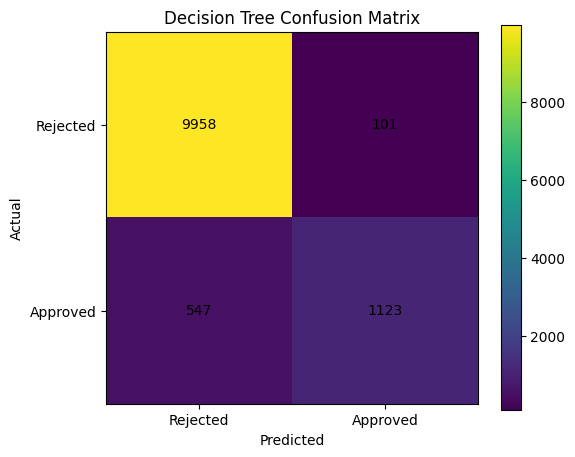

In [49]:
cm = confusion_matrix(
    y_test,
    y_pred
)

plt.figure(figsize=(6, 5))

plt.imshow(cm)

plt.title("Decision Tree Confusion Matrix")

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.xticks(
    [0, 1],
    ["Rejected", "Approved"]
)

plt.yticks(
    [0, 1],
    ["Rejected", "Approved"]
)

for i in range(2):
    for j in range(2):
        plt.text(
            j,
            i,
            str(cm[i, j]),
            ha="center",
            va="center"
        )

plt.colorbar()

plt.show()

In [50]:
tree_model = model.named_steps[
    "classifier"
]

feature_names = model.named_steps[
    "preprocessor"
].get_feature_names_out()

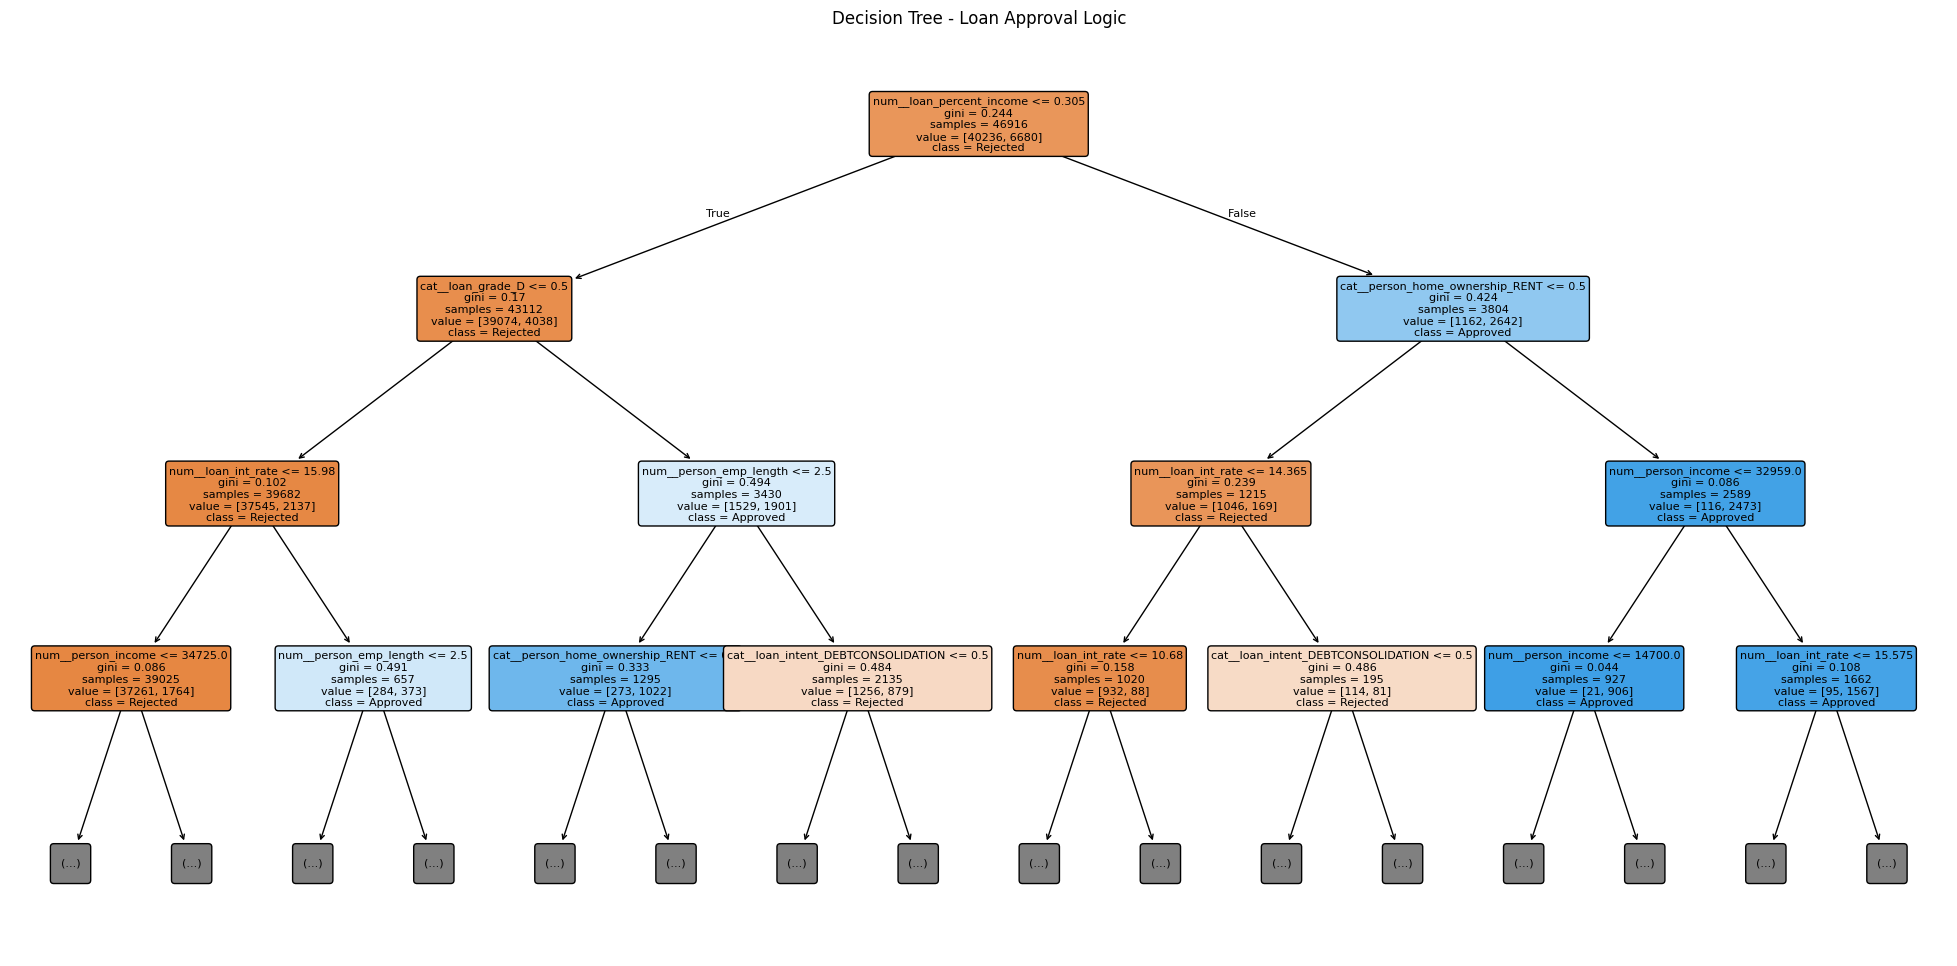

In [51]:
plt.figure(
    figsize=(25, 12)
)

plot_tree(
    tree_model,
    feature_names=feature_names,
    class_names=[
        "Rejected",
        "Approved"
    ],
    filled=True,
    rounded=True,
    max_depth=3,
    fontsize=8
)

plt.title(
    "Decision Tree - Loan Approval Logic"
)

plt.show()

In [52]:
feature_importance = pd.DataFrame({
    "Feature": feature_names,
    "Importance": tree_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

feature_importance.head(15)

,Feature,Importance
5,num__loan_percent_income,0.365435
20,cat__loan_grade_D,0.228947
10,cat__person_home_ownership_RENT,0.191908
4,num__loan_int_rate,0.056994
14,cat__loan_intent_MEDICAL,0.047177
2,num__person_emp_length,0.040153
11,cat__loan_intent_DEBTCONSOLIDATION,0.037552
13,cat__loan_intent_HOMEIMPROVEMENT,0.011828
1,num__person_income,0.011607
21,cat__loan_grade_E,0.004976


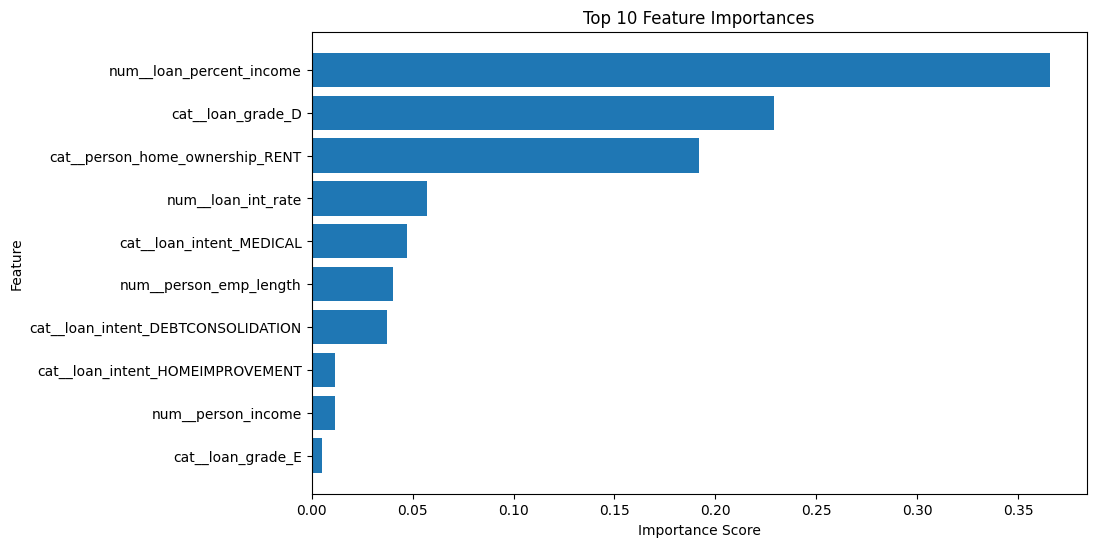

In [53]:
top_features = feature_importance.head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_features["Feature"],
    top_features["Importance"]
)

plt.xlabel("Importance Score")

plt.ylabel("Feature")

plt.title(
    "Top 10 Feature Importances"
)

plt.gca().invert_yaxis()

plt.show()

In [54]:
print(X.columns.tolist())

['person_age', 'person_income', 'person_home_ownership', 'person_emp_length', 'loan_intent', 'loan_grade', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_default_on_file', 'cb_person_cred_hist_length']


In [55]:
def predict_loan(
    person_age,
    person_income,
    person_home_ownership,
    person_emp_length,
    loan_intent,
    loan_grade,
    loan_amnt,
    loan_int_rate,
    loan_percent_income,
    cb_person_default_on_file,
    cb_person_cred_hist_length
):

    try:

        input_data = pd.DataFrame(
            [[
                person_age,
                person_income,
                person_home_ownership,
                person_emp_length,
                loan_intent,
                loan_grade,
                loan_amnt,
                loan_int_rate,
                loan_percent_income,
                cb_person_default_on_file,
                cb_person_cred_hist_length
            ]],

            columns=[
                "person_age",
                "person_income",
                "person_home_ownership",
                "person_emp_length",
                "loan_intent",
                "loan_grade",
                "loan_amnt",
                "loan_int_rate",
                "loan_percent_income",
                "cb_person_default_on_file",
                "cb_person_cred_hist_length"
            ]
        )

        probability = float(
            model.predict_proba(input_data)[0][1]
        )

        prediction_value = int(
            model.predict(input_data)[0]
        )

        prediction = (
            "High Default Risk"
            if prediction_value == 1
            else "Low Default Risk"
        )

        return {
            "Prediction": prediction,
            "Default Risk Probability": f"{probability:.2%}",
            "Model": "Decision Tree",
            "Inference Status": "Completed Successfully"
        }

    except Exception as e:

        return {
            "Prediction": "Error",
            "Details": str(e)
        }

In [56]:
!pip install -q gradio

import gradio as gr


with gr.Blocks(
    title="Loan Default Risk Assessment"
) as demo:

    gr.Markdown("""
    # Loan Default Risk Assessment

    ### Decision Tree Model Inference

    Enter applicant and loan information to evaluate
    the predicted risk of loan default.
    """)


    with gr.Row():

        with gr.Column():

            person_age = gr.Number(
                value=30,
                label="Applicant Age"
            )

            person_income = gr.Number(
                value=60000,
                label="Annual Income"
            )

            person_home_ownership = gr.Dropdown(
                choices=[
                    "RENT",
                    "OWN",
                    "MORTGAGE",
                    "OTHER"
                ],
                value="RENT",
                label="Home Ownership"
            )

            person_emp_length = gr.Number(
                value=5,
                label="Employment Length (Years)"
            )

            loan_intent = gr.Dropdown(
                choices=[
                    "PERSONAL",
                    "EDUCATION",
                    "MEDICAL",
                    "VENTURE",
                    "HOMEIMPROVEMENT",
                    "DEBTCONSOLIDATION"
                ],
                value="PERSONAL",
                label="Loan Purpose"
            )

            loan_grade = gr.Dropdown(
                choices=[
                    "A",
                    "B",
                    "C",
                    "D",
                    "E",
                    "F",
                    "G"
                ],
                value="B",
                label="Loan Grade"
            )


        with gr.Column():

            loan_amnt = gr.Number(
                value=10000,
                label="Loan Amount"
            )

            loan_int_rate = gr.Number(
                value=12.5,
                label="Loan Interest Rate (%)"
            )

            loan_percent_income = gr.Number(
                value=0.17,
                label="Loan Amount / Income Ratio"
            )

            cb_person_default_on_file = gr.Dropdown(
                choices=[
                    "Y",
                    "N"
                ],
                value="N",
                label="Previous Default History"
            )

            cb_person_cred_hist_length = gr.Number(
                value=8,
                label="Credit History Length (Years)"
            )


    predict_button = gr.Button(
        "Run Risk Assessment",
        variant="primary"
    )


    output = gr.JSON(
        label="Decision Tree Prediction Result"
    )


    predict_button.click(

        fn=predict_loan,

        inputs=[
            person_age,
            person_income,
            person_home_ownership,
            person_emp_length,
            loan_intent,
            loan_grade,
            loan_amnt,
            loan_int_rate,
            loan_percent_income,
            cb_person_default_on_file,
            cb_person_cred_hist_length
        ],

        outputs=output
    )


demo.launch(
    debug=True,
    share=True
)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://cbbedca45f4150613e.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://3336337ec1a7c6bed3.gradio.live
Killing tunnel 127.0.0.1:7861 <> https://cbbedca45f4150613e.gradio.live
